# Part 2: Variance reduction

**The question:** how much more precise can a Monte Carlo price become at the same computational budget?

Plain Monte Carlo has an error of $s/\sqrt{n}$: halving it costs four times as many paths. Variance reduction attacks $s$ instead of $n$. We compare plain Monte Carlo with antithetic variates, a control variate, and both combined. To keep the comparison fair, $n$ is always the total number of payoff evaluations, and each variance is measured from repeated independent runs rather than taken from a reported standard error.

In [1]:
import matplotlib.pyplot as plt
import matplotlib.ticker
import numpy as np
import pandas as pd

import mc_utils as mc

mc.set_plot_style()
S0, K, r, sigma, T = 100.0, 100.0, 0.05, 0.2, 1.0
rng = np.random.default_rng(42)

METHODS = {
    "Plain MC": mc.price_european,
    "Antithetic": mc.price_antithetic,
    "Control variate": mc.price_control_variate,
    "Combined": mc.price_combined,
}
COLORS = {
    "Plain MC": mc.BLUE,
    "Antithetic": mc.ORANGE,
    "Control variate": mc.AQUA,
    "Combined": mc.MAGENTA,
}
MARKERS = {"Plain MC": "o", "Antithetic": "s", "Control variate": "^", "Combined": "D"}


def moneyness(option, strike):
    if strike == S0:
        return "ATM"
    in_the_money = strike < S0 if option == "call" else strike > S0
    return "ITM" if in_the_money else "OTM"

## 1. The three methods

**Antithetic variates.** Draw $n/2$ normals and use each one twice, as $Z$ and $-Z$. A high stock price is paired with a low one, so the two payoffs partly cancel:

$$\hat V^{\text{AV}} = \frac{1}{n/2}\sum_{i=1}^{n/2} \frac{X(Z_i) + X(-Z_i)}{2}.$$

The $n/2$ pair averages are independent, but the two members of a pair are not. So the standard error must be computed from the pair averages, not from the $n$ payoffs.

**Control variate.** Take a quantity whose exact mean we know, here the discounted stock $Y = e^{-rT}S_T$ with $\mathbb{E}[Y] = S_0$. On each path we can see how far $Y$ is from its mean, and we correct the payoff $X$ by that known error:

$$\hat V^{\text{CV}} = \frac{1}{n}\sum_{i=1}^{n}\Big(X_i - \beta\,\big(Y_i - \mathbb{E}[Y]\big)\Big), \qquad \beta^* = \frac{\operatorname{Cov}(X,Y)}{\operatorname{Var}(Y)}.$$

With the best $\beta$ the variance is divided by $1/(1-\rho^2)$, where $\rho$ is the correlation between $X$ and $Y$. Estimating $\beta$ on the same sample adds a bias of order $1/n$, negligible next to the $1/\sqrt{n}$ statistical error.

**Combined.** Apply the control variate to the antithetic pair averages.

In [2]:
exact = mc.bs_price(S0, K, r, sigma, T, "call")
rows = []
for n in (10_000, 100_000):
    for name, pricer in METHODS.items():
        res = pricer(S0, K, r, sigma, T, n, rng=rng)
        rows.append(
            {
                "method": name,
                "n": n,
                "MC price": res["price"],
                "std error": res["std_error"],
                "CI low": res["ci_low"],
                "CI high": res["ci_high"],
                "Black-Scholes": exact,
                "CI contains BS": res["ci_low"] <= exact <= res["ci_high"],
            }
        )
pd.DataFrame(rows).round(4)

,method,n,MC price,std error,CI low,CI high,Black-Scholes,CI contains BS
0,Plain MC,10000,10.3452,0.1477,10.0558,10.6346,10.4506,True
1,Antithetic,10000,10.4289,0.1042,10.2246,10.6333,10.4506,True
2,Control variate,10000,10.4111,0.0557,10.3019,10.5203,10.4506,True
3,Combined,10000,10.4539,0.0276,10.3999,10.5079,10.4506,True
4,Plain MC,100000,10.3799,0.0468,10.2883,10.4716,10.4506,True
5,Antithetic,100000,10.4738,0.0329,10.4092,10.5384,10.4506,True
6,Control variate,100000,10.4352,0.0177,10.4004,10.4699,10.4506,True
7,Combined,100000,10.4606,0.0086,10.4438,10.4775,10.4506,True


Every interval contains the exact price, and the standard error falls sharply from method to method. The combined estimator with 10,000 paths (standard error 0.0276) is more precise than plain Monte Carlo with 100,000 paths (0.0468).

## 2. Variance reduction by strike

A single run proves little, so we measure the variance properly. Each method prices the same option 500 times with $n = 10{,}000$, and the variance reduction (VR) factor is

$$\text{VR factor} = \frac{\operatorname{Var}(\text{plain MC price})}{\operatorname{Var}(\text{method price})}.$$

We do this for calls and puts that are in the money (ITM), at the money (ATM) and out of the money (OTM).

In [3]:
rows = []
for option in ("call", "put"):
    for strike in (80.0, 100.0, 120.0):
        params = dict(S0=S0, K=strike, r=r, sigma=sigma, T=T, n=10_000, option=option)
        variances = {name: mc.price_variance(f, 500, rng, **params) for name, f in METHODS.items()}
        row = {"option": option, "K": strike, "moneyness": moneyness(option, strike)}
        for name in ("Antithetic", "Control variate", "Combined"):
            row[name] = variances["Plain MC"] / variances[name]
        rows.append(row)
study = pd.DataFrame(rows)
study.round(2)

,option,K,moneyness,Antithetic,Control variate,Combined
0,call,80.0,ITM,7.84,61.34,537.63
1,call,100.0,ATM,2.41,7.36,31.92
2,call,120.0,OTM,1.18,2.50,55.10
3,put,80.0,OTM,1.07,1.31,9.61
4,put,100.0,ATM,1.58,2.19,9.34
5,put,120.0,ITM,13.17,6.21,188.54


For the at-the-money call the variance falls by 2.41x with antithetics, 7.36x with the control variate and 31.92x with both. The gain depends strongly on the contract, from 1.07x (antithetics on the OTM put) to 537.63x (combined on the ITM call).

## 3. Theory check for the control variate

Theory predicts a factor of $1/(1-\rho^2)$. We estimate $\rho$ from one run of 1,000,000 paths and compare the prediction with the factor measured above.

In [4]:
rows = []
for _, row in study.iterrows():
    res = mc.price_control_variate(S0, row["K"], r, sigma, T, 1_000_000, row["option"], rng=rng)
    rows.append(
        {
            "option": row["option"],
            "K": row["K"],
            "moneyness": row["moneyness"],
            "rho": round(res["rho"], 4),
            "predicted 1/(1-rho^2)": round(1 / (1 - res["rho"] ** 2), 2),
            "measured factor": round(row["Control variate"], 2),
        }
    )
pd.DataFrame(rows)

,option,K,moneyness,rho,predicted 1/(1-rho^2),measured factor
0,call,80.0,ITM,0.9922,63.97,61.34
1,call,100.0,ATM,0.9243,6.87,7.36
2,call,120.0,OTM,0.7515,2.30,2.50
3,put,80.0,OTM,-0.4446,1.25,1.31
4,put,100.0,ATM,-0.7612,2.38,2.19
5,put,120.0,ITM,-0.9228,6.74,6.21


The prediction works: 6.87 predicted against 7.36 measured for the at-the-money call, 63.97 against 61.34 for the ITM call. With 500 runs each variance is uncertain by about 6%, so a ratio of two variances is uncertain by about 9%, and all six gaps are within that noise. The sign of $\rho$ does not matter: a put is negatively correlated with the stock, which works just as well.

## 4. Same rate, lower error

Variance reduction changes the constant in front of $1/\sqrt{n}$, not the rate. We check this on the at-the-money call with 300 runs at each sample size, using even sample sizes so that antithetic pairs are possible.

Plain MC: fitted slope -0.5086


Antithetic: fitted slope -0.4893


Control variate: fitted slope -0.4865


Combined: fitted slope -0.5047


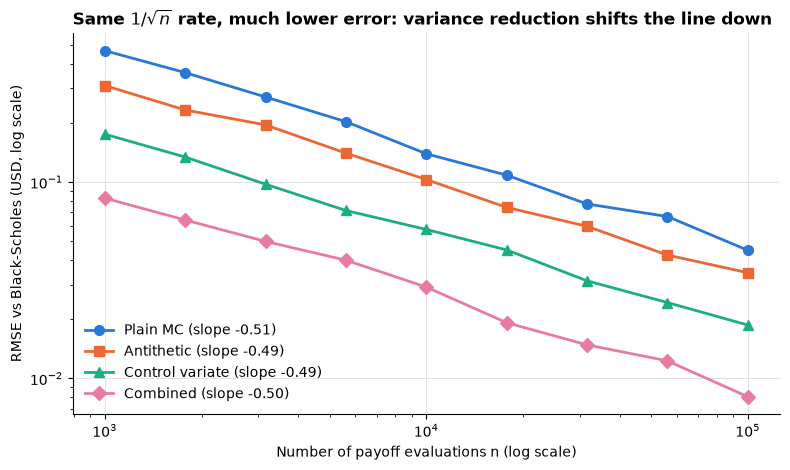

In [5]:
ns = np.unique(2 * np.round(np.geomspace(1e3, 1e5, 9) / 2).astype(int))
fig, ax = plt.subplots(figsize=(8, 4.8))
for name, pricer in METHODS.items():
    rmse = []
    for n in ns:
        errors = [pricer(S0, K, r, sigma, T, int(n), rng=rng)["price"] - exact for _ in range(300)]
        rmse.append(np.sqrt(np.mean(np.square(errors))))
    slope = np.polyfit(np.log(ns), np.log(rmse), 1)[0]
    print(f"{name}: fitted slope {slope:.4f}")
    ax.plot(
        ns,
        rmse,
        marker=MARKERS[name],
        markersize=7,
        color=COLORS[name],
        label=f"{name} (slope {slope:.2f})",
    )
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Number of payoff evaluations n (log scale)")
ax.set_ylabel("RMSE vs Black-Scholes (USD, log scale)")
ax.set_title(r"Same $1/\sqrt{n}$ rate, much lower error: variance reduction shifts the line down")
ax.legend(loc="lower left")
fig.tight_layout()
fig.savefig("figures/04_error_vs_n.png")
plt.show()

All four fitted slopes are close to -0.5 (between -0.4865 and -0.5086). The four lines are parallel: each method keeps the same rate and only moves the line down.

## 5. Where each method helps

The chart shows the factors of section 2 for each strike.

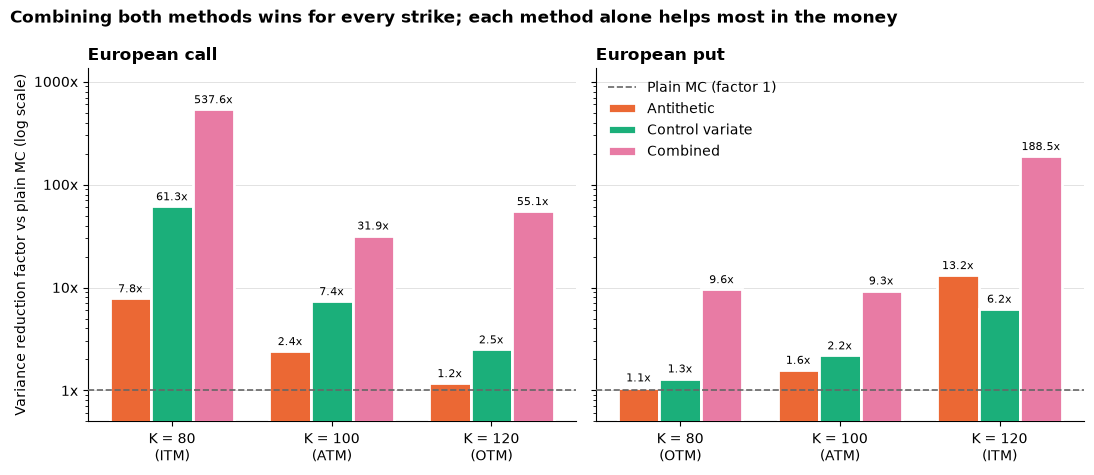

In [6]:
methods = ["Antithetic", "Control variate", "Combined"]
strikes = (80.0, 100.0, 120.0)
width = 0.26

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), sharey=True)
for ax, option in zip(axes, ("call", "put")):
    sub = study[study["option"] == option]
    for i, name in enumerate(methods):
        positions = np.arange(len(strikes)) + (i - 1) * width
        # White edges leave a visible gap between adjacent bars.
        ax.bar(
            positions,
            sub[name],
            width,
            color=COLORS[name],
            edgecolor="white",
            linewidth=2,
            label=name,
            zorder=3,
        )
        for x, factor in zip(positions, sub[name]):
            ax.text(x, factor * 1.08, f"{factor:.1f}x", ha="center", va="bottom", fontsize=8)
    ax.axhline(
        1.0, color=mc.GREY, linestyle="--", linewidth=1.2, label="Plain MC (factor 1)", zorder=4
    )
    ax.set_xticks(range(len(strikes)), [f"K = {s:.0f}\n({moneyness(option, s)})" for s in strikes])
    ax.set_yscale("log")
    ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:g}x"))
    ax.grid(axis="x", visible=False)
    ax.set_title(f"European {option}")
axes[0].set_ylabel("Variance reduction factor vs plain MC (log scale)")
axes[0].set_ylim(0.5, study[methods].to_numpy().max() * 2.5)
axes[1].legend(loc="upper left")  # the OTM bars are short, so this corner is free
fig.suptitle(
    "Combining both methods wins for every strike; each method alone helps most in the money",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=12,
)
fig.tight_layout()
fig.savefig("figures/05_variance_reduction_by_strike.png")
plt.show()

**Where the control variate helps most: in-the-money calls.** A deep ITM call behaves almost like the stock itself, so its payoff is almost perfectly correlated with $S_T$ and the variance falls by 61.34x at $K = 80$.

**Where it helps little: out-of-the-money options.** For the OTM call most payoffs are zero whatever the exact value of $S_T$ (factor 2.50). For the OTM put the payoff only depends on the lower tail (factor 1.31).

**Antithetics** follow the same pattern. They remove the part of the payoff that is odd in $Z$, so they work when the payoff is close to linear in $Z$ (7.84x for the ITM call, 13.17x for the ITM put) and barely help for one-sided, convex OTM payoffs (1.18x and 1.07x).

**Why combining does far better than either method alone.** On the OTM call the two methods alone give 1.18x and 2.50x, but together 55.10x. The antithetic pair average removes the odd part of the payoff and leaves its even, convex part. The averaged control $\tfrac{1}{2}\big(Y(Z)+Y(-Z)\big)$ is proportional to $\cosh(\sigma\sqrt{T}Z)$, also even and convex, so it is strongly correlated with what remains. The two methods attack different parts of the variance.

## Key takeaways

- At equal budget, the variance of the at-the-money call falls by 2.41x with antithetics, 7.36x with the control variate and 31.92x with both.
- The gain depends on the contract: large in the money, small out of the money, and the theory $1/(1-\rho^2)$ predicts the control variate factor well.
- Variance reduction lowers the constant, not the $1/\sqrt{n}$ rate. The two methods work best together because they remove different parts of the variance.